# ACA 1 · Aprendizaje Automático
## Pilar Ventas · Segmentación de clientes con RFM y K-Means · Dataset UCI Online Retail

**Corporación Unificada Nacional de Educación Superior (CUN)** · Especialización en Inteligencia Artificial
**Asignatura:** Aprendizaje Automático · **Docente:** Dr. Hamilton Rivera Flor · **Grupo 1**

**Integrantes:** Mayra Fernanda Bernate Bustamante · Angela Consuelo Castillo Rodríguez · Karen Viviana Ospina Lesmes · Jair Vargas · Santiago Bahamón Escobar

**Fuente:** Chen, D. (2015). *Online Retail* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

**Pregunta orientadora:** ¿cómo transformar los datos transaccionales de una tienda en línea en conocimiento accionable mediante técnicas clásicas de Machine Learning, y presentarlo en una interfaz interactiva para el equipo comercial?

**Problema concreto:** la tienda trata igual a 4.300 clientes con comportamientos muy distintos. Se busca agruparlos según cuándo compraron por última vez, con qué frecuencia y cuánto gastan (RFM), para dirigir a cada grupo una acción comercial distinta.

| Paso | Contenido | Estado |
|---|---|---|
| 1 | Exploración y EDA | Desarrollado |
| 2 | Limpieza y preprocesamiento | Desarrollado |
| 3 | Modelado clásico: RFM + K-Means | Desarrollado |
| 4 | Evaluación: métricas internas, estabilidad y perfiles | Desarrollado |
| 5 | Despliegue Streamlit (`app/`) | Desarrollado |

## 0. Configuración del entorno

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Paleta institucional (tonos verdes)
VERDE = "#1B7A3E"
VERDE_CLARO = "#7FBF8F"
GRIS = "#6B6B6B"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
RAW_FILE = Path("online+retail") / "Online Retail.xlsx"
CLEAN_FILE = DATA_DIR / "online_retail_clean.csv"


# PASO 1 · Exploración y comprensión del problema

### 1.1 Contexto
El dataset registra todas las transacciones de una tienda en línea con sede en Reino Unido entre el 1 de diciembre de 2010 y el 9 de diciembre de 2011. La empresa vende artículos de regalo para toda ocasión, y buena parte de sus clientes son mayoristas.

### 1.2 Diccionario de variables
| Variable | Tipo | Descripción |
|---|---|---|
| InvoiceNo | Texto | Número de factura. Si empieza con "C" es una cancelación |
| StockCode | Texto | Código del producto (SKU) |
| Description | Texto | Nombre del producto |
| Quantity | Entero | Unidades por línea de factura |
| InvoiceDate | Fecha y hora | Momento de la transacción |
| UnitPrice | Decimal | Precio unitario en libras esterlinas |
| CustomerID | Entero | Identificador del cliente |
| Country | Texto | País del cliente |


### 1.3 Carga de datos

In [2]:
df_raw = pd.read_excel(
    RAW_FILE,
    dtype={"InvoiceNo": str, "StockCode": str, "Description": str},
)
print(f"Filas: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 541,909 | Columnas: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 59.5 MB


### 1.4 Estadística descriptiva

In [4]:
df_raw.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"


**Lectura:** `Quantity` y `UnitPrice` tienen valores negativos y extremos (±80.995 unidades, precios de −11.062). Estos valores indican devoluciones, ajustes contables o errores de digitación que el Paso 2 debe tratar.

### 1.5 Calidad de datos: valores faltantes

In [5]:
faltantes = pd.DataFrame({
    "faltantes": df_raw.isna().sum(),
    "% del total": df_raw.isna().mean() * 100,
})
faltantes[faltantes["faltantes"] > 0]

,faltantes,% del total
Description,1454,0.27
CustomerID,135080,24.93


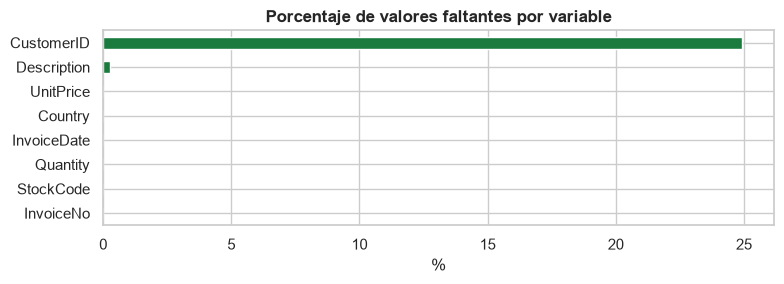

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
(df_raw.isna().mean() * 100).sort_values().plot.barh(ax=ax, color=VERDE)
ax.set_title("Porcentaje de valores faltantes por variable")
ax.set_xlabel("%")
plt.tight_layout(); plt.show()

**Lectura:** cerca de una de cada cuatro líneas no tiene `CustomerID`. Esas ventas existen, pero no se pueden atribuir a un cliente. Esto define qué preguntas se pueden responder con cada parte del dataset.

### 1.6 Calidad de datos: registros problemáticos

In [7]:
problemas = pd.Series({
    "Filas duplicadas exactas": df_raw.duplicated().sum(),
    "Facturas canceladas (InvoiceNo con 'C')": df_raw["InvoiceNo"].str.startswith("C").sum(),
    "Quantity <= 0": (df_raw["Quantity"] <= 0).sum(),
    "UnitPrice <= 0": (df_raw["UnitPrice"] <= 0).sum(),
    "StockCode no producto (POST, DOT, M, BANK CHARGES...)": (~df_raw["StockCode"].str.match(r"^\d{5}")).sum(),
}, name="registros")
problemas.to_frame()

,registros
Filas duplicadas exactas,5268
Facturas canceladas (InvoiceNo con 'C'),9288
Quantity <= 0,10624
UnitPrice <= 0,2517
"StockCode no producto (POST, DOT, M, BANK CHARGES...)",2995


In [8]:
no_producto = df_raw.loc[~df_raw["StockCode"].str.match(r"^\d{5}"), ["StockCode", "Description"]]
no_producto.groupby("StockCode")["Description"].first().head(15)

StockCode
AMAZONFEE                       AMAZON FEE
B                          Adjust bad debt
BANK CHARGES                  Bank Charges
C2                                CARRIAGE
CRUK                       CRUK Commission
D                                 Discount
DCGS0003               BOXED GLASS ASHTRAY
DCGS0004        HAYNES CAMPER SHOULDER BAG
DCGS0055                               NaN
DCGS0057                               NaN
DCGS0066P                              NaN
DCGS0067                              ebay
DCGS0068                              ebay
DCGS0069             OOH LA LA DOGS COLLAR
DCGS0070             CAMOUFLAGE DOG COLLAR
Name: Description, dtype: str

### 1.7 Dimensión del negocio

In [9]:
resumen = pd.Series({
    "Facturas": df_raw["InvoiceNo"].nunique(),
    "Productos (SKU)": df_raw["StockCode"].nunique(),
    "Clientes identificados": df_raw["CustomerID"].nunique(),
    "Países": df_raw["Country"].nunique(),
    "Fecha inicial": df_raw["InvoiceDate"].min(),
    "Fecha final": df_raw["InvoiceDate"].max(),
})
resumen.to_frame("valor")

,valor
Facturas,25900
Productos (SKU),4070
Clientes identificados,4372
Países,38
Fecha inicial,2010-12-01 08:26:00
Fecha final,2011-12-09 12:50:00


# PASO 2 · Limpieza y preprocesamiento

Cada regla se aplica en orden y se registra cuántas filas elimina. Así el proceso queda trazable y reproducible.

In [10]:
bitacora = []
def registrar(paso, antes, despues):
    bitacora.append({"regla": paso, "filas antes": antes, "filas eliminadas": antes - despues, "filas después": despues})

df = df_raw.copy()

### 2.1 Eliminar duplicados exactos
Una misma línea repetida (misma factura, producto, cantidad, hora y precio) es un error de registro y duplica la venta.

In [11]:
n = len(df)
df = df.drop_duplicates()
registrar("Duplicados exactos", n, len(df))

### 2.2 Separar cancelaciones
Las facturas que empiezan con "C" son devoluciones. Se guardan aparte para analizar la tasa de devolución y se excluyen del conjunto de ventas.

In [12]:
n = len(df)
cancelaciones = df[df["InvoiceNo"].str.startswith("C")].copy()
df = df[~df["InvoiceNo"].str.startswith("C")]
registrar("Cancelaciones (InvoiceNo 'C')", n, len(df))
print(f"Cancelaciones separadas: {len(cancelaciones):,} líneas")

Cancelaciones separadas: 9,251 líneas


### 2.3 Eliminar cantidades y precios no válidos
Una venta real tiene cantidad y precio positivos. Los registros con cero o negativos corresponden a ajustes de inventario, muestras gratis o deudas incobrables.

In [13]:
n = len(df)
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
registrar("Quantity o UnitPrice <= 0", n, len(df))

### 2.4 Eliminar códigos que no son productos
`POST` (envío), `DOT` (franqueo), `M` (ajuste manual), `BANK CHARGES`, `AMAZONFEE` y similares son cargos administrativos. Mezclarlos con productos distorsiona cualquier análisis de demanda o de comportamiento de compra. Se conservan los SKU numéricos de 5 dígitos, con o sin letra al final (ejemplo: 85123A).

In [14]:
n = len(df)
df = df[df["StockCode"].str.match(r"^\d{5}[A-Za-z]*$")]
registrar("Códigos no producto", n, len(df))

### 2.5 Tratamiento de `CustomerID` faltante
No se imputa: inventar un cliente crearía comportamientos falsos. Se mantiene la venta y se marca con la variable `tiene_cliente`. Así cada análisis posterior decide si necesita el cliente identificado.

In [15]:
df["tiene_cliente"] = df["CustomerID"].notna()
df["CustomerID"] = df["CustomerID"].astype("Int64")
df["tiene_cliente"].value_counts(normalize=True).rename("proporción").to_frame()

,proporción
tiene_cliente,
True,0.75
False,0.25


### 2.6 Valores extremos
Se revisan las líneas con cantidades muy altas. Se usa el percentil 99,9 como referencia.

In [16]:
p999 = df["Quantity"].quantile(0.999)
print(f"Percentil 99,9 de Quantity: {p999:,.0f} unidades")
df.nlargest(5, "Quantity")[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate"]]

Percentil 99,9 de Quantity: 456 unidades


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446,2011-12-09 09:15:00
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346,2011-01-18 10:01:00
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,12901,2011-10-27 12:26:00
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,13135,2011-05-27 10:52:00
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,18087,2011-02-22 10:43:00


**Decisión:** las dos líneas más grandes (80.995 y 74.215 unidades) fueron canceladas el mismo día por el mismo cliente. Su contraparte negativa ya salió con las cancelaciones, por lo que la venta original queda sin anular y debe retirarse. El resto de cantidades altas corresponde a compras mayoristas reales y se conserva.

In [17]:
n = len(df)
pares_cancelados = cancelaciones.assign(Quantity=-cancelaciones["Quantity"])[["StockCode", "CustomerID", "Quantity"]]
pares_cancelados = pares_cancelados[pares_cancelados["Quantity"] >= 10_000]
llave = ["StockCode", "CustomerID", "Quantity"]
df = df.merge(pares_cancelados.drop_duplicates().assign(_anulada=True), on=llave, how="left")
df = df[df["_anulada"].isna()].drop(columns="_anulada")
registrar("Ventas extremas anuladas por cancelación", n, len(df))

### 2.7 Variables derivadas
Se crean variables básicas de valor y de tiempo, útiles para cualquier enfoque de modelado.

In [18]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df["Date"] = df["InvoiceDate"].dt.date
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)
df["Week"] = df["InvoiceDate"].dt.to_period("W").dt.start_time
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()
df["Hour"] = df["InvoiceDate"].dt.hour
df["Description"] = df["Description"].str.strip().str.upper()
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,tiene_cliente,Revenue,Date,YearMonth,Week,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,True,15.30,2010-12-01,2010-12,2010-11-29,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,20.34,2010-12-01,2010-12,2010-11-29,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,True,22.00,2010-12-01,2010-12,2010-11-29,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,20.34,2010-12-01,2010-12,2010-11-29,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,20.34,2010-12-01,2010-12,2010-11-29,Wednesday,8


### 2.8 Bitácora de limpieza

In [19]:
bitacora_df = pd.DataFrame(bitacora)
bitacora_df["% eliminado"] = bitacora_df["filas eliminadas"] / len(df_raw) * 100
bitacora_df

,regla,filas antes,filas eliminadas,filas después,% eliminado
0,Duplicados exactos,541909,5268,536641,0.97
1,Cancelaciones (InvoiceNo 'C'),536641,9251,527390,1.71
2,Quantity o UnitPrice <= 0,527390,2512,524878,0.46
3,Códigos no producto,524878,2374,522504,0.44
4,Ventas extremas anuladas por cancelación,522504,2,522502,0.00


In [20]:
print(f"Filas originales: {len(df_raw):,}")
print(f"Filas limpias:    {len(df):,} ({len(df)/len(df_raw):.0%} del original)")

Filas originales: 541,909
Filas limpias:    522,502 (96% del original)


# Análisis exploratorio sobre los datos limpios

### Evolución mensual de ingresos

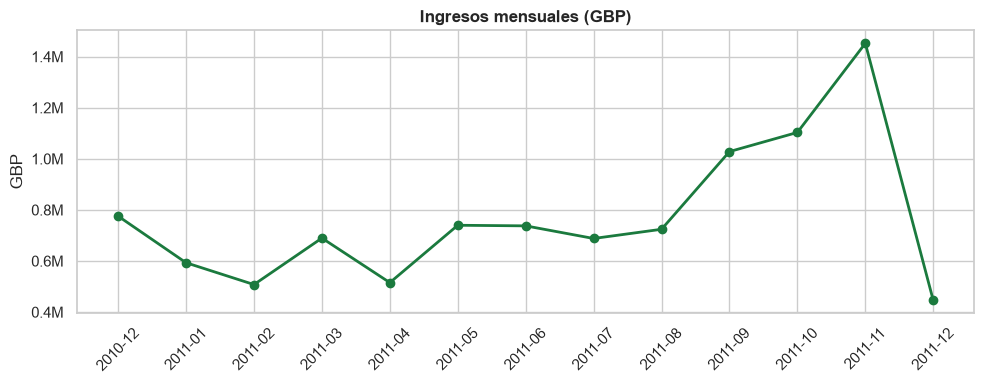

Nota: diciembre de 2011 solo tiene 9 días de datos.


In [21]:
mensual = df.groupby("YearMonth").agg(ingresos=("Revenue", "sum"), facturas=("InvoiceNo", "nunique"))
fig, ax = plt.subplots()
mensual["ingresos"].plot(ax=ax, color=VERDE, marker="o", lw=2)
ax.set_title("Ingresos mensuales (GBP)")
ax.set_xlabel(""); ax.set_ylabel("GBP")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
plt.xticks(range(len(mensual)), mensual.index, rotation=45)
plt.tight_layout(); plt.show()
print("Nota: diciembre de 2011 solo tiene 9 días de datos.")

### Concentración por país

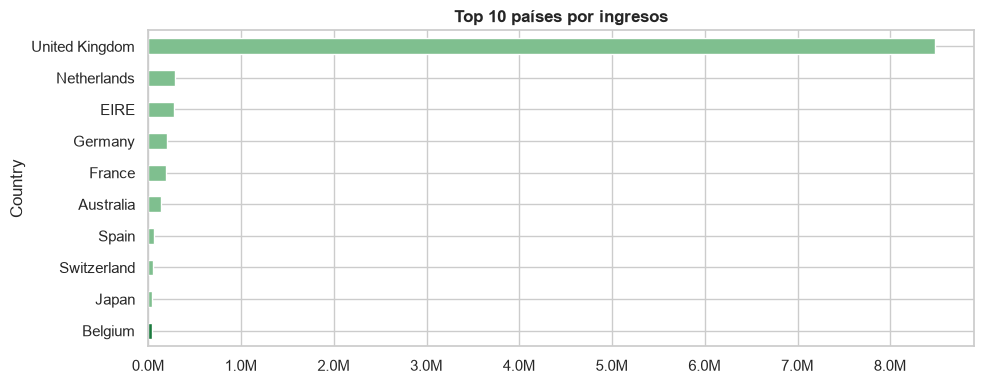

Reino Unido concentra 85% de los ingresos


In [22]:
pais = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
top = pais.head(10)
fig, ax = plt.subplots()
top[::-1].plot.barh(ax=ax, color=[VERDE] + [VERDE_CLARO] * 9)
ax.set_title("Top 10 países por ingresos")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
plt.tight_layout(); plt.show()
print(f"Reino Unido concentra {pais.iloc[0]/pais.sum():.0%} de los ingresos")

### Productos más vendidos

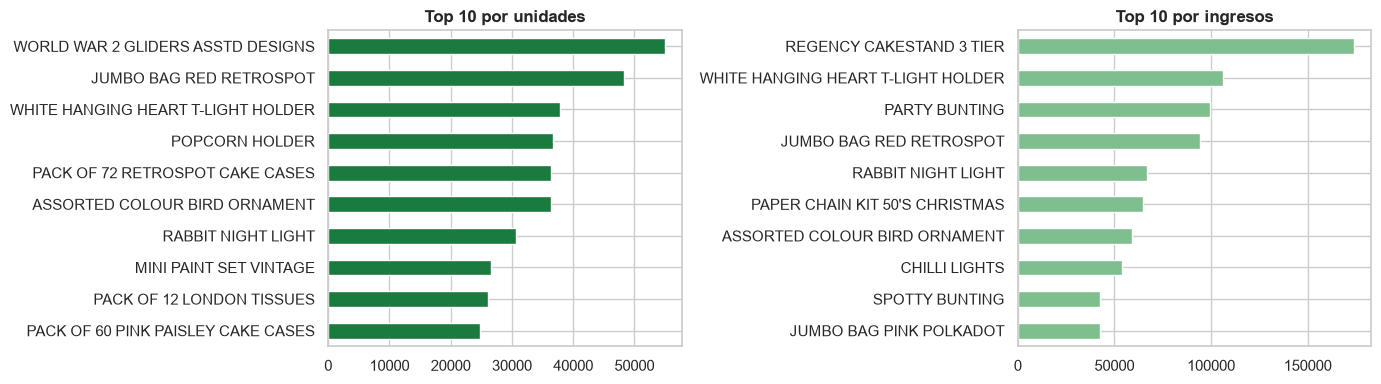

In [23]:
prod = df.groupby("Description").agg(unidades=("Quantity", "sum"), ingresos=("Revenue", "sum"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
prod["unidades"].nlargest(10)[::-1].plot.barh(ax=axes[0], color=VERDE, title="Top 10 por unidades")
prod["ingresos"].nlargest(10)[::-1].plot.barh(ax=axes[1], color=VERDE_CLARO, title="Top 10 por ingresos")
for a in axes: a.set_ylabel("")
plt.tight_layout(); plt.show()

### Patrón por día y hora

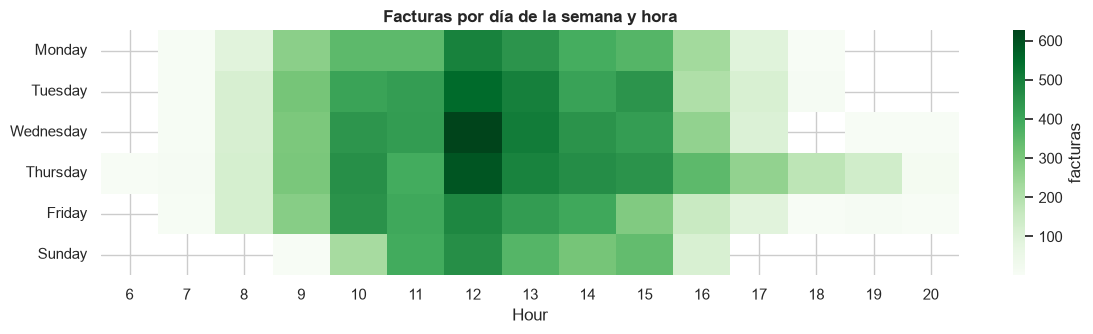

In [24]:
orden = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
mapa = df.pivot_table(index="DayOfWeek", columns="Hour", values="InvoiceNo", aggfunc="nunique").reindex(orden).dropna(how="all")
fig, ax = plt.subplots(figsize=(12, 3.5))
sns.heatmap(mapa, cmap="Greens", ax=ax, cbar_kws={"label": "facturas"})
ax.set_title("Facturas por día de la semana y hora"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### Vista por cliente (solo ventas con CustomerID)

In [25]:
cli = df[df["tiene_cliente"]].groupby("CustomerID").agg(
    facturas=("InvoiceNo", "nunique"),
    gasto=("Revenue", "sum"),
    ultima_compra=("InvoiceDate", "max"),
)
cli.describe()

,facturas,gasto,ultima_compra
count,"4,333.00","4,333.00",4333
mean,4.25,"1,959.74",2011-09-08 07:47:46.346642
min,1.00,2.90,2010-12-01 09:53:00
25%,1.00,303.97,2011-07-20 10:51:00
50%,2.00,661.32,2011-10-20 09:40:00
75%,5.00,"1,628.56",2011-11-22 10:59:00
max,206.00,"279,138.02",2011-12-09 12:50:00
std,7.64,"8,461.15",NaN


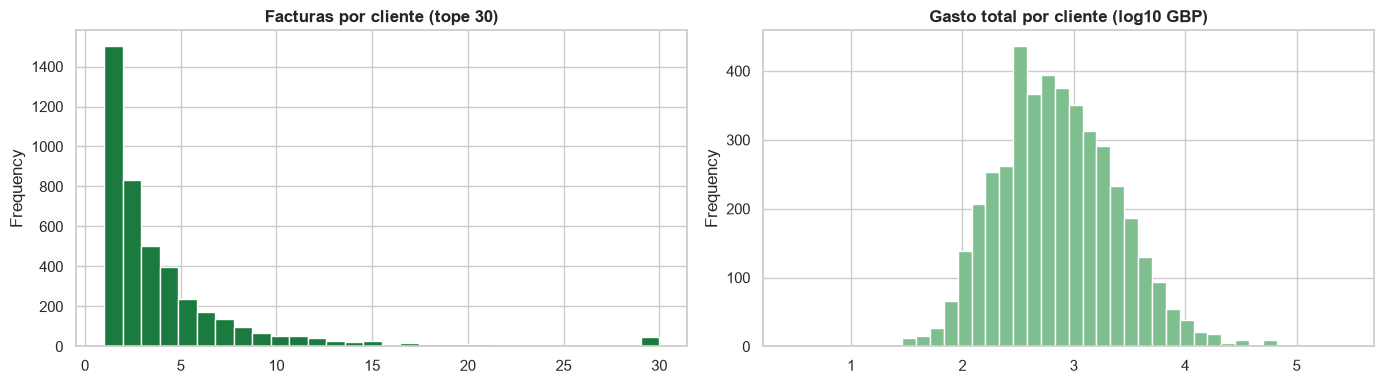

El 20% de clientes con mayor gasto genera 74% del ingreso
Clientes con una sola factura: 35%


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
cli["facturas"].clip(upper=30).plot.hist(bins=30, ax=axes[0], color=VERDE, title="Facturas por cliente (tope 30)")
np.log10(cli["gasto"]).plot.hist(bins=40, ax=axes[1], color=VERDE_CLARO, title="Gasto total por cliente (log10 GBP)")
plt.tight_layout(); plt.show()

top20 = cli["gasto"].sort_values(ascending=False)
print(f"El 20% de clientes con mayor gasto genera {top20.head(int(len(top20)*0.2)).sum()/top20.sum():.0%} del ingreso")
print(f"Clientes con una sola factura: {(cli['facturas']==1).mean():.0%}")

### Vista por producto en el tiempo

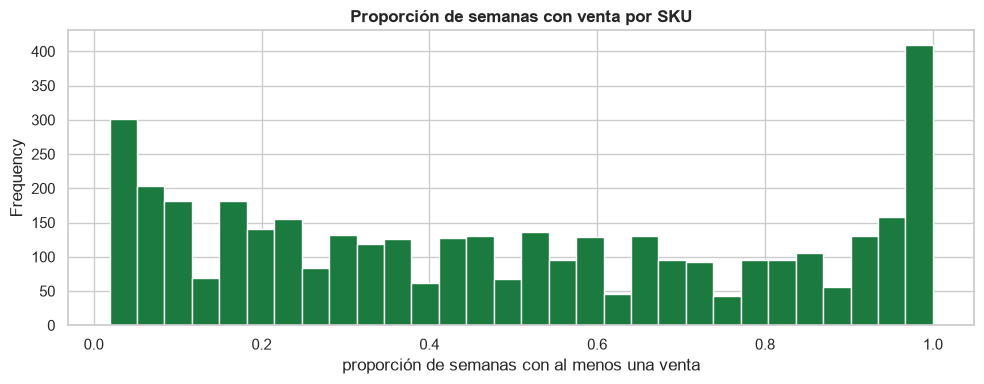

SKU vendidos en menos de la mitad de las semanas: 53%


In [27]:
semana_sku = df.groupby(["StockCode", "Week"])["Quantity"].sum().unstack(fill_value=0)
semanas_con_venta = (semana_sku > 0).mean(axis=1)
fig, ax = plt.subplots()
semanas_con_venta.plot.hist(bins=30, ax=ax, color=VERDE)
ax.set_title("Proporción de semanas con venta por SKU"); ax.set_xlabel("proporción de semanas con al menos una venta")
plt.tight_layout(); plt.show()
print(f"SKU vendidos en menos de la mitad de las semanas: {(semanas_con_venta < 0.5).mean():.0%}")

### Tasa de devolución

In [28]:
tasa = (-cancelaciones["Quantity"] * cancelaciones["UnitPrice"]).sum() / df["Revenue"].sum()
print(f"Valor cancelado frente a ventas netas: {tasa:.1%}")

Valor cancelado frente a ventas netas: 8.9%


### 2.9 Exportar dataset limpio

In [29]:
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "Revenue",
        "InvoiceDate", "Date", "YearMonth", "Week", "DayOfWeek", "Hour",
        "CustomerID", "tiene_cliente", "Country"]
df[cols].to_csv(CLEAN_FILE, index=False)
print(f"Guardado: {CLEAN_FILE} ({len(df):,} filas)")

Guardado: data\online_retail_clean.csv (522,502 filas)


## Hallazgos de los Pasos 1 y 2

- El dataset original tiene más de medio millón de líneas de factura de un año de operación.
- Cerca de una cuarta parte de las líneas no identifica al cliente. Se conservan para análisis de ventas y se excluyen cuando el análisis requiere al cliente.
- Duplicados, cancelaciones, precios en cero y cargos administrativos se retiraron con reglas trazables. El dataset limpio conserva cerca del 96% de las líneas originales.
- La venta tiene estacionalidad marcada: crece desde septiembre y alcanza su pico en noviembre por la temporada de regalos.
- Reino Unido concentra cerca del 85% del ingreso.
- El 20% de los clientes genera cerca de tres cuartas partes del ingreso, y cerca de un tercio compra una sola vez.
- Cerca de la mitad de los productos se vende en menos de la mitad de las semanas, lo que hace su demanda irregular.
- Las cancelaciones equivalen a cerca del 9% del valor vendido.

**Siguiente paso:** con los datos limpios se construyen las variables RFM por cliente y se entrena el modelo (Paso 3).

# PASO 3 · Modelado clásico

### 3.1 Formulación del problema y elección del enfoque
El dataset **no tiene una variable objetivo** (no hay una etiqueta de "tipo de cliente"), así que el problema es de **aprendizaje no supervisado**: agrupar clientes parecidos.

Se usa el modelo **RFM**, estándar en marketing para describir el valor de un cliente:
- **Recencia (R):** días desde la última compra hasta el día siguiente a la última fecha del dataset.
- **Frecuencia (F):** número de facturas distintas.
- **Monetario (M):** gasto total en libras.

Solo se usan las ventas con `CustomerID` (el 75 % de las líneas), porque RFM describe clientes.

In [30]:
ventas_cli = df[df["tiene_cliente"]].copy()
fecha_ref = ventas_cli["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = ventas_cli.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda s: (fecha_ref - s.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
).reset_index()

print(f"Fecha de referencia: {fecha_ref:%Y-%m-%d} | Clientes: {len(rfm):,}")
rfm[["Recency", "Frequency", "Monetary"]].describe().T

Fecha de referencia: 2011-12-10 | Clientes: 4,333


,count,mean,std,min,25%,50%,75%,max
Recency,"4,333.00",92.70,100.13,1.00,18.00,51.00,143.00,374.00
Frequency,"4,333.00",4.25,7.64,1.00,1.00,2.00,5.00,206.00
Monetary,"4,333.00","1,959.74","8,461.15",2.90,303.97,661.32,"1,628.56","279,138.02"


### 3.2 Preprocesamiento de las variables RFM
K-Means usa distancia euclidiana, así que necesita variables con escala comparable y sin colas extremas:
1. **Transformación logarítmica (`log1p`)**: F y M tienen asimetría muy fuerte (unos pocos mayoristas gastan cientos de veces más que la mediana). Sin la transformación, esos clientes dominarían la distancia y formarían clústeres de uno o dos individuos.
2. **Estandarización (`StandardScaler`)**: lleva las tres variables a media 0 y desviación 1, para que ninguna pese más por su unidad de medida (días frente a libras).

,asimetría original,asimetría tras log1p
Recency,1.24,-0.38
Frequency,11.95,1.21
Monetary,20.92,0.36


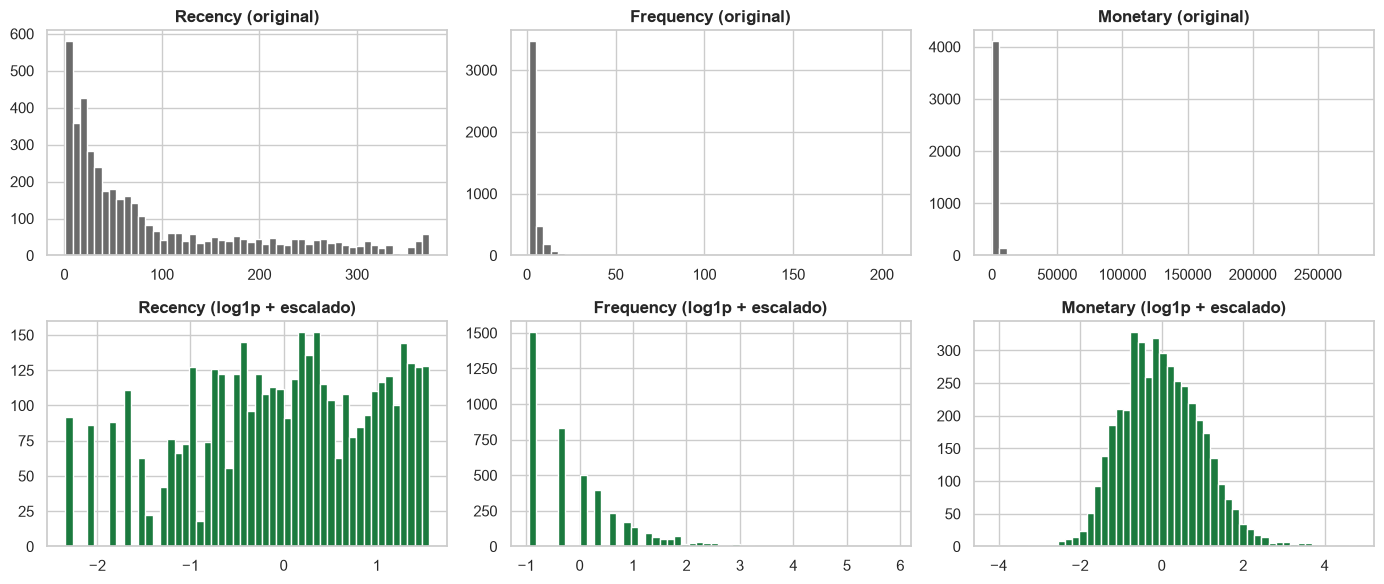

In [31]:
from sklearn.preprocessing import StandardScaler

COLUMNAS = ["Recency", "Frequency", "Monetary"]
X_log = np.log1p(rfm[COLUMNAS])
scaler = StandardScaler()
X = scaler.fit_transform(X_log)

display(pd.DataFrame({"asimetría original": rfm[COLUMNAS].skew(),
                      "asimetría tras log1p": X_log.skew()}).round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for j, col in enumerate(COLUMNAS):
    axes[0, j].hist(rfm[col], bins=50, color=GRIS); axes[0, j].set_title(f"{col} (original)")
    axes[1, j].hist(X[:, j], bins=50, color=VERDE); axes[1, j].set_title(f"{col} (log1p + escalado)")
plt.tight_layout(); plt.show()

### 3.3 Selección del número de clústeres (K)
Se entrena K-Means con K entre 2 y 8 y se comparan cuatro criterios:
- **Inercia (método del codo):** suma de distancias al centroide. Siempre baja con K; se busca el punto donde deja de bajar rápido.
- **Silhouette (−1 a 1, mayor es mejor):** qué tan separado está cada cliente de los otros grupos frente a su propio grupo.
- **Davies-Bouldin (≥ 0, menor es mejor):** parecido promedio entre cada clúster y el más cercano.
- **Calinski-Harabasz (mayor es mejor):** dispersión entre clústeres frente a la dispersión dentro de ellos.

,Inercia,Silhouette,Davies-Bouldin,Calinski-Harabasz
K,,,,
2,"6,467.15",0.43,0.89,"4,374.33"
3,"4,849.93",0.34,1.04,"3,637.84"
4,"3,921.95",0.34,1.01,"3,339.77"
5,"3,278.02",0.32,0.98,"3,208.72"
6,"2,837.62",0.31,1.02,"3,099.08"
7,"2,533.05",0.31,0.97,"2,979.05"
8,"2,324.30",0.29,1.01,"2,837.67"


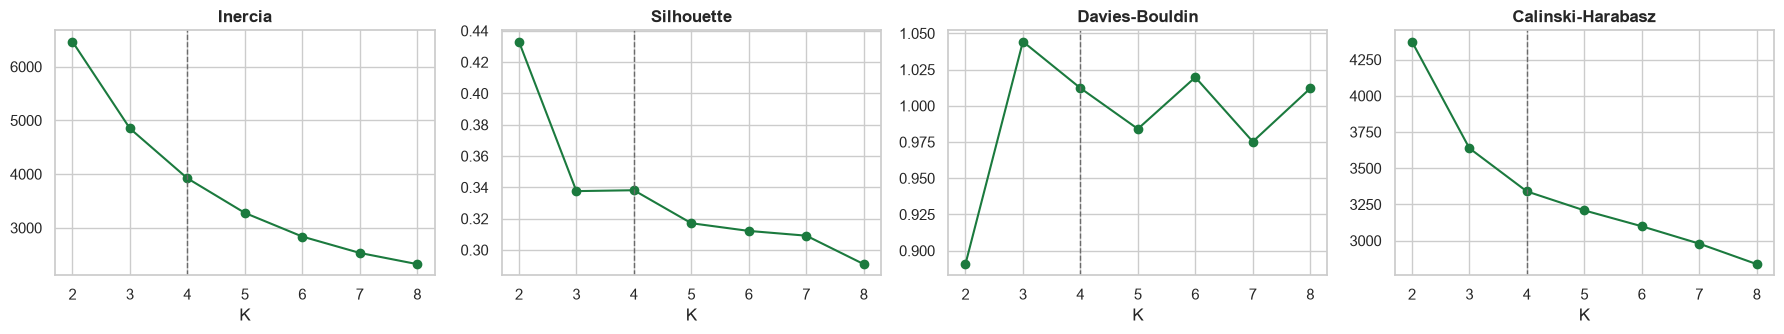

In [32]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

res_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    res_k.append({"K": k, "Inercia": km.inertia_,
                  "Silhouette": silhouette_score(X, km.labels_),
                  "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
                  "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_)})
res_k = pd.DataFrame(res_k).set_index("K")
display(res_k.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, res_k.columns):
    ax.plot(res_k.index, res_k[col], marker="o", color=VERDE)
    ax.axvline(4, color=GRIS, ls="--", lw=1)
    ax.set_title(col); ax.set_xlabel("K")
plt.tight_layout(); plt.show()

**Decisión: K = 4.**
- K = 2 obtiene el mejor Silhouette, pero solo separa clientes "activos" de "inactivos". Esa división ya se conoce y no permite acciones diferenciadas.
- A partir de K = 4 la inercia baja más despacio (codo) y Silhouette y Davies-Bouldin se estabilizan: K mayores no mejoran la separación y fragmentan grupos pequeños.
- K = 4 coincide con los segmentos clásicos del marketing RFM (campeones, leales, nuevos, en riesgo o perdidos), cada uno con una estrategia comercial distinta.

Se privilegia un K **interpretable y accionable** con métricas aceptables, en lugar del óptimo matemático de una sola métrica.

### 3.4 Entrenamiento del modelo final
`KMeans(n_clusters=4, n_init=10, random_state=42)`: 10 inicializaciones k-means++ para evitar mínimos locales y semilla fija para que el resultado sea reproducible.

In [33]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
rfm["Cluster"] = kmeans.labels_

perfil = rfm.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"), Recencia=("Recency", "mean"),
    Frecuencia=("Frequency", "mean"), Gasto=("Monetary", "mean"))
perfil

,Clientes,Recencia,Frecuencia,Gasto
Cluster,,,,
0,685,11.84,13.96,"7,934.68"
1,1637,182.75,1.33,349.86
2,834,18.26,2.12,532.96
3,1177,67.25,4.16,"1,732.46"


### 3.5 Asignación de nombres a los segmentos
Los números de clúster que entrega K-Means son arbitrarios. Para que el nombre no dependa de la semilla, se asigna con reglas sobre el perfil:
- **Campeones:** mayor gasto promedio.
- **Perdidos / inactivos:** mayor recencia (más días sin comprar).
- De los dos restantes, el de **menor frecuencia** son **Nuevos / recientes** y el otro **Clientes leales**.

In [34]:
campeones = perfil["Gasto"].idxmax()
perdidos = perfil.drop(campeones)["Recencia"].idxmax()
restantes = perfil.drop([campeones, perdidos])
nuevos = restantes["Frecuencia"].idxmin()
leales = restantes.drop(nuevos).index[0]

mapa_nombres = {int(campeones): "Campeones", int(leales): "Clientes leales",
                int(nuevos): "Nuevos / recientes", int(perdidos): "Perdidos / inactivos"}
ORDEN = ["Campeones", "Clientes leales", "Nuevos / recientes", "Perdidos / inactivos"]
rfm["Segmento"] = rfm["Cluster"].map(mapa_nombres)
perfil.rename(index=mapa_nombres).loc[ORDEN].round(1)

,Clientes,Recencia,Frecuencia,Gasto
Cluster,,,,
Campeones,685,11.80,14.00,"7,934.70"
Clientes leales,1177,67.20,4.20,"1,732.50"
Nuevos / recientes,834,18.30,2.10,533.00
Perdidos / inactivos,1637,182.80,1.30,349.90


### 3.6 Comparación con otros algoritmos clásicos
Para justificar la elección, se entrenan dos alternativas con K = 4 sobre los mismos datos:
- **Clustering jerárquico aglomerativo (Ward):** no asume clústeres esféricos, pero no puede asignar clientes nuevos sin reentrenar y su costo crece con el cuadrado del número de clientes.
- **Mezcla de gaussianas (GMM):** asignación probabilística, con clústeres elípticos.

El **Adjusted Rand Index (ARI)** mide cuánto coinciden sus grupos con los de K-Means (1 = idénticos, 0 = coincidencia al azar).

In [35]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

modelos = {
    "K-Means": kmeans.labels_,
    "Jerárquico (Ward)": AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X),
    "GMM": GaussianMixture(n_components=K, n_init=5, random_state=42).fit(X).predict(X),
}
comparacion = pd.DataFrame([{
    "Algoritmo": nombre,
    "Silhouette": silhouette_score(X, et), "Davies-Bouldin": davies_bouldin_score(X, et),
    "Calinski-Harabasz": calinski_harabasz_score(X, et),
    "ARI vs K-Means": adjusted_rand_score(kmeans.labels_, et),
    "Predice clientes nuevos": nombre != "Jerárquico (Ward)",
} for nombre, et in modelos.items()]).set_index("Algoritmo")
comparacion.round(3)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI vs K-Means,Predice clientes nuevos
Algoritmo,,,,,
K-Means,0.34,1.01,"3,339.77",1.00,True
Jerárquico (Ward),0.26,1.20,"2,689.02",0.42,False
GMM,0.17,1.71,"2,179.48",0.43,True


**Lectura:** K-Means obtiene las mejores métricas internas en los tres criterios (Silhouette 0,34 frente a 0,26 y 0,17; Davies-Bouldin 1,01 frente a 1,20 y 1,71). Las alternativas coinciden con K-Means solo de forma moderada (ARI ≈ 0,42): los clientes forman un continuo más que islas separadas, y cada algoritmo traza las fronteras de forma distinta. Por eso conviene el criterio que mejor separa y que además se puede explicar y desplegar. K-Means se elige porque:
1. Asigna un cliente nuevo al centroide más cercano (`predict`), lo que la app de Streamlit necesita.
2. Escala linealmente con el número de clientes.
3. Sus centroides se explican directamente en términos de R, F y M.

# PASO 4 · Evaluación

### 4.1 Métricas internas del modelo final
En aprendizaje no supervisado no hay exactitud ni matriz de confusión, porque no existe etiqueta real. La calidad se mide con métricas internas de cohesión y separación, con la estabilidad del resultado y con la utilidad de negocio de los segmentos.

In [36]:
metricas = pd.Series({
    "Silhouette": silhouette_score(X, kmeans.labels_),
    "Davies-Bouldin": davies_bouldin_score(X, kmeans.labels_),
    "Calinski-Harabasz": calinski_harabasz_score(X, kmeans.labels_),
    "Inercia": kmeans.inertia_,
}).round(3)
metricas.to_frame("K-Means, K = 4")

,"K-Means, K = 4"
Silhouette,0.34
Davies-Bouldin,1.01
Calinski-Harabasz,"3,339.77"
Inercia,"3,921.95"


,Silhouette medio,% clientes con silhouette < 0
Segmento,,
Campeones,0.31,6.42
Clientes leales,0.30,0.68
Nuevos / recientes,0.26,2.52
Perdidos / inactivos,0.42,0.06


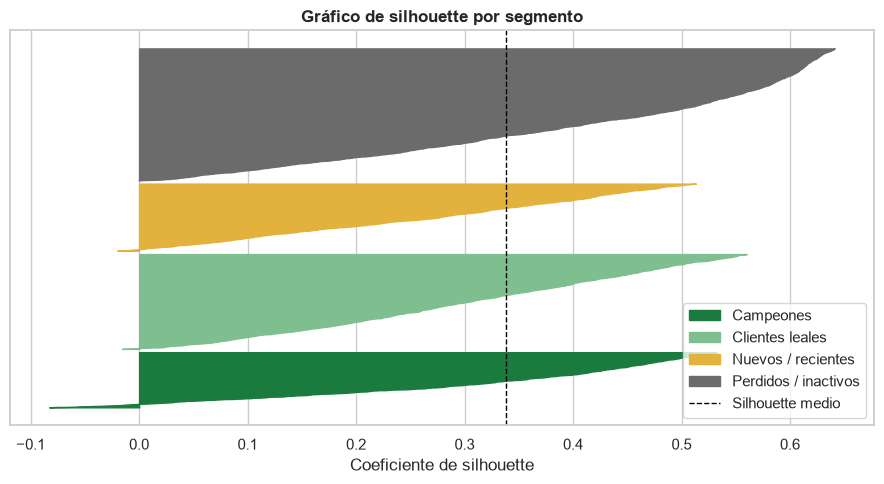

In [37]:
from sklearn.metrics import silhouette_samples

sil = silhouette_samples(X, kmeans.labels_)
rfm["silhouette"] = sil
display(rfm.groupby("Segmento")["silhouette"].agg(["mean", lambda s: (s < 0).mean() * 100])
        .rename(columns={"mean": "Silhouette medio", "<lambda_0>": "% clientes con silhouette < 0"}).loc[ORDEN].round(3))

fig, ax = plt.subplots(figsize=(9, 5))
y0 = 0
colores = dict(zip(ORDEN, [VERDE, VERDE_CLARO, "#E3B23C", GRIS]))
for seg in ORDEN:
    v = np.sort(rfm.loc[rfm["Segmento"] == seg, "silhouette"].values)
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=colores[seg], label=seg)
    y0 += len(v) + 40
ax.axvline(metricas["Silhouette"], color="black", ls="--", lw=1, label="Silhouette medio")
ax.set_title("Gráfico de silhouette por segmento"); ax.set_xlabel("Coeficiente de silhouette"); ax.set_yticks([])
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 4.2 Estabilidad del modelo
Un buen agrupamiento no debe cambiar al variar la semilla ni al quitar una parte de los clientes. Se mide:
- **Semillas:** 10 entrenamientos con semillas distintas, comparados con el modelo final mediante ARI.
- **Submuestreo:** 10 entrenamientos con el 80 % de los clientes elegidos al azar; se compara la asignación de esos clientes con la del modelo final.

In [38]:
rng = np.random.default_rng(0)
ari_semillas = [adjusted_rand_score(kmeans.labels_, KMeans(K, n_init=10, random_state=s).fit_predict(X)) for s in range(10)]
ari_sub = []
for s in range(10):
    idx = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
    km_s = KMeans(K, n_init=10, random_state=s).fit(X[idx])
    ari_sub.append(adjusted_rand_score(kmeans.labels_[idx], km_s.labels_))

pd.DataFrame({"ARI medio": [np.mean(ari_semillas), np.mean(ari_sub)],
              "ARI mínimo": [np.min(ari_semillas), np.min(ari_sub)]},
             index=["10 semillas", "10 submuestras del 80 %"]).round(3)

,ARI medio,ARI mínimo
10 semillas,0.98,0.95
10 submuestras del 80 %,0.96,0.89


### 4.3 Visualización de los segmentos

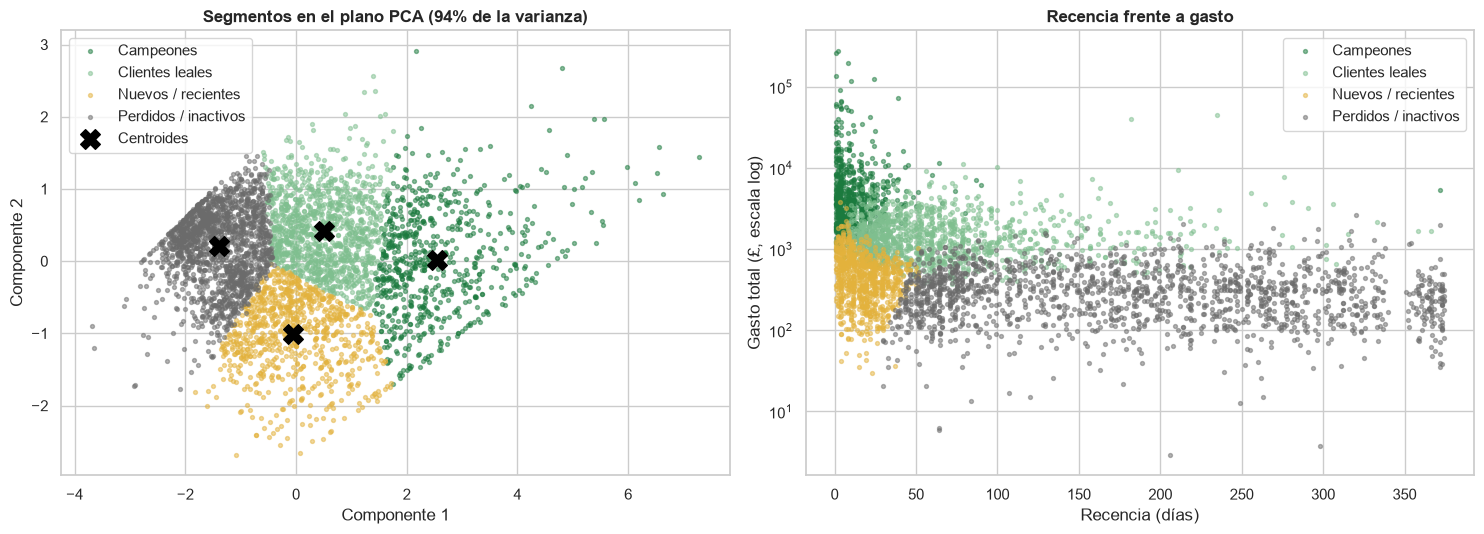

In [39]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
centros = pca.transform(kmeans.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for seg in ORDEN:
    m = rfm["Segmento"] == seg
    axes[0].scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, color=colores[seg], label=seg)
axes[0].scatter(centros[:, 0], centros[:, 1], marker="X", s=200, color="black", label="Centroides")
axes[0].set_title(f"Segmentos en el plano PCA ({pca.explained_variance_ratio_.sum():.0%} de la varianza)")
axes[0].set_xlabel("Componente 1"); axes[0].set_ylabel("Componente 2"); axes[0].legend()

for seg in ORDEN:
    m = rfm["Segmento"] == seg
    axes[1].scatter(rfm.loc[m, "Recency"], rfm.loc[m, "Monetary"], s=8, alpha=0.5, color=colores[seg], label=seg)
axes[1].set_yscale("log"); axes[1].set_xlabel("Recencia (días)"); axes[1].set_ylabel("Gasto total (£, escala log)")
axes[1].set_title("Recencia frente a gasto"); axes[1].legend()
plt.tight_layout(); plt.show()

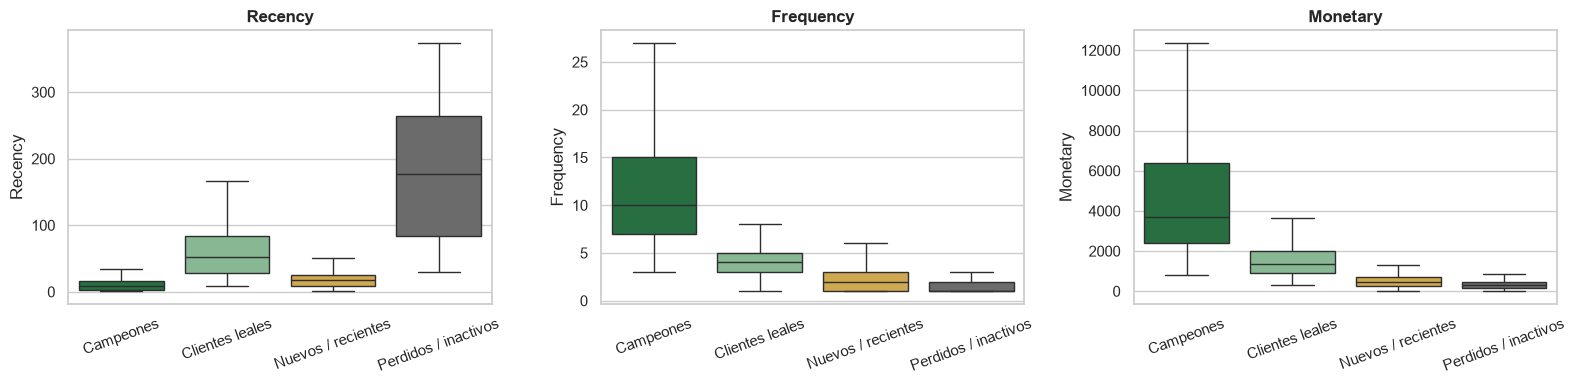

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, COLUMNAS):
    sns.boxplot(data=rfm, x="Segmento", y=col, order=ORDEN, palette=colores, ax=ax, showfliers=False)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

### 4.4 Utilidad de negocio de los segmentos
La validación final es comercial: ¿los segmentos separan clientes con valor distinto? Se compara la proporción de clientes de cada segmento con su participación en el ingreso.

,Clientes,Recencia_media,Frecuencia_media,Gasto_medio,Ingreso_total,% clientes,% ingresos
Segmento,,,,,,,
Campeones,685,11.80,14.00,"7,934.70","5,435,257.30",15.80,64.00
Clientes leales,1177,67.20,4.20,"1,732.50","2,039,107.80",27.20,24.00
Nuevos / recientes,834,18.30,2.10,533.00,"444,492.50",19.20,5.20
Perdidos / inactivos,1637,182.80,1.30,349.90,"572,716.80",37.80,6.70


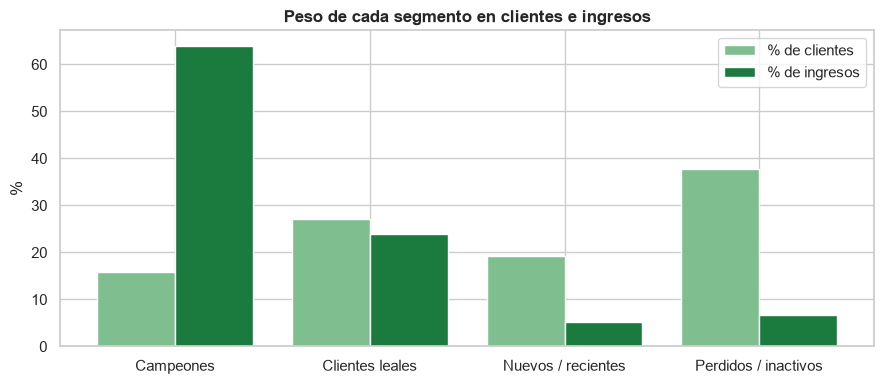

In [41]:
resumen = rfm.groupby("Segmento").agg(
    Clientes=("CustomerID", "count"), Recencia_media=("Recency", "mean"),
    Frecuencia_media=("Frequency", "mean"), Gasto_medio=("Monetary", "mean"),
    Ingreso_total=("Monetary", "sum")).loc[ORDEN]
resumen["% clientes"] = resumen["Clientes"] / resumen["Clientes"].sum() * 100
resumen["% ingresos"] = resumen["Ingreso_total"] / resumen["Ingreso_total"].sum() * 100
display(resumen.round(1))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(ORDEN))
ax.bar(x - 0.2, resumen["% clientes"], 0.4, color=VERDE_CLARO, label="% de clientes")
ax.bar(x + 0.2, resumen["% ingresos"], 0.4, color=VERDE, label="% de ingresos")
ax.set_xticks(x, ORDEN); ax.set_ylabel("%"); ax.legend(); ax.set_title("Peso de cada segmento en clientes e ingresos")
plt.tight_layout(); plt.show()

In [42]:
r = resumen.round(1)
print(f"Silhouette = {metricas['Silhouette']:.3f} | Davies-Bouldin = {metricas['Davies-Bouldin']:.3f} | "
      f"ARI estabilidad (semillas) = {np.mean(ari_semillas):.3f} | ARI (submuestras) = {np.mean(ari_sub):.3f}")
for seg in ORDEN:
    print(f"{seg:22s} {r.loc[seg, '% clientes']:5.1f} % de clientes -> {r.loc[seg, '% ingresos']:5.1f} % de ingresos | "
          f"recencia {r.loc[seg, 'Recencia_media']:.0f} d, {r.loc[seg, 'Frecuencia_media']:.1f} compras, £{r.loc[seg, 'Gasto_medio']:,.0f}")

Silhouette = 0.338 | Davies-Bouldin = 1.012 | ARI estabilidad (semillas) = 0.977 | ARI (submuestras) = 0.962
Campeones               15.8 % de clientes ->  64.0 % de ingresos | recencia 12 d, 14.0 compras, £7,935
Clientes leales         27.2 % de clientes ->  24.0 % de ingresos | recencia 67 d, 4.2 compras, £1,732
Nuevos / recientes      19.2 % de clientes ->   5.2 % de ingresos | recencia 18 d, 2.1 compras, £533
Perdidos / inactivos    37.8 % de clientes ->   6.7 % de ingresos | recencia 183 d, 1.3 compras, £350


### 4.5 Interpretación y recomendaciones

| Segmento | Perfil | Acción comercial |
|---|---|---|
| **Campeones** | Compran seguido, hace poco y gastan mucho. Pocos clientes, gran parte del ingreso | Programa de recompensas, acceso anticipado, atención preferente. Evitar descuentos innecesarios |
| **Clientes leales** | Frecuencia y gasto medios; última compra hace unos dos meses | Venta cruzada y aumento del valor del pedido, para convertirlos en campeones |
| **Nuevos / recientes** | Compraron hace poco pero una o dos veces | Incentivo para la segunda compra (cupón con vencimiento corto) |
| **Perdidos / inactivos** | Meses sin comprar, baja frecuencia y gasto | Campañas de reactivación de bajo costo; no invertir presupuesto alto |

**Lectura de las métricas.** Un Silhouette de ≈ 0,34 indica una estructura moderada. Es habitual en datos de comportamiento de clientes, donde los grupos son continuos y no islas separadas. El ARI cercano a 1 entre semillas y submuestras muestra que los segmentos son **estables**: no son un artefacto de la inicialización. La diferencia entre la participación en clientes y en ingresos confirma que la segmentación tiene **valor de negocio**: los Campeones son el 16 % de los clientes y generan el 64 % del ingreso, mientras que los Perdidos / inactivos son el 38 % de los clientes y aportan menos del 7 %.

**Limitaciones.** RFM no usa qué productos compra cada cliente ni su país. Con los datos de un solo año, la recencia está acotada a 374 días. Los mayoristas con gasto extremo quedan dentro de Campeones.

# PASO 5 · Despliegue en Streamlit

El modelo se exporta como un diccionario con todo lo necesario para clasificar un cliente nuevo con **el mismo preprocesamiento** del notebook (`log1p` → `StandardScaler` → `KMeans.predict`):

| Clave | Contenido |
|---|---|
| `scaler` | `StandardScaler` ajustado |
| `kmeans` | Modelo K-Means entrenado |
| `mapa_nombres` | Número de clúster → nombre del segmento |
| `columnas` | Orden de las variables (`Recency`, `Frequency`, `Monetary`) |
| `resumen` | Perfil medio de cada segmento, para la pestaña de resumen |
| `version_sklearn` | Versión de scikit-learn usada, que debe coincidir en `requirements.txt` |

La app está en `app/app.py`. Para ejecutarla localmente:
```
cd app
pip install -r requirements.txt
streamlit run app.py
```
Para publicarla: subir la carpeta `app/` a GitHub y desplegarla en Streamlit Community Cloud (share.streamlit.io → *New app* → `app.py`).

In [43]:
import joblib, sklearn
from pathlib import Path

APP_DIR = Path("app"); APP_DIR.mkdir(exist_ok=True)
modelo = {
    "scaler": scaler, "kmeans": kmeans, "mapa_nombres": mapa_nombres, "columnas": COLUMNAS,
    "resumen": resumen[["Clientes", "Recencia_media", "Frecuencia_media", "Gasto_medio"]].round(1)
               .reset_index().to_dict("records"),
    "version_sklearn": sklearn.__version__,
}
joblib.dump(modelo, APP_DIR / "modelo_rfm.pkl")
print(f"Modelo guardado en {APP_DIR / 'modelo_rfm.pkl'} (scikit-learn {sklearn.__version__})")

Modelo guardado en app\modelo_rfm.pkl (scikit-learn 1.9.1)


### 5.1 Prueba de la función de predicción de la app
Se recarga el archivo exportado y se clasifican clientes de ejemplo con la misma función que usa `app.py`. Además, se verifica que el modelo exportado reproduzca exactamente los segmentos del notebook.

In [44]:
cargado = joblib.load(APP_DIR / "modelo_rfm.pkl")

def clasificar(modelo, recencia, frecuencia, monetario):
    entrada = pd.DataFrame([[recencia, frecuencia, monetario]], columns=modelo["columnas"])
    escalada = modelo["scaler"].transform(np.log1p(entrada))
    return modelo["mapa_nombres"][int(modelo["kmeans"].predict(escalada)[0])]

ejemplos = pd.DataFrame([
    {"caso": "Mayorista activo", "Recency": 5, "Frequency": 40, "Monetary": 25000},
    {"caso": "Cliente habitual", "Recency": 20, "Frequency": 6, "Monetary": 1800},
    {"caso": "Primera compra reciente", "Recency": 10, "Frequency": 1, "Monetary": 250},
    {"caso": "Sin comprar hace 10 meses", "Recency": 300, "Frequency": 1, "Monetary": 150},
])
ejemplos["Segmento predicho"] = [clasificar(cargado, r.Recency, r.Frequency, r.Monetary) for r in ejemplos.itertuples()]
display(ejemplos)

reproduce = (cargado["kmeans"].predict(cargado["scaler"].transform(np.log1p(rfm[COLUMNAS]))) == kmeans.labels_).mean()
print(f"Coincidencia del modelo exportado con el notebook: {reproduce:.1%}")

,caso,Recency,Frequency,Monetary,Segmento predicho
0,Mayorista activo,5,40,25000,Campeones
1,Cliente habitual,20,6,1800,Clientes leales
2,Primera compra reciente,10,1,250,Nuevos / recientes
3,Sin comprar hace 10 meses,300,1,150,Perdidos / inactivos


Coincidencia del modelo exportado con el notebook: 100.0%


# Conclusiones

1. **Calidad de datos.** De 541.909 líneas se conservó el 96 % tras reglas trazables (duplicados, cancelaciones, precios inválidos, cargos no producto y pedidos atípicos anulados). Los clientes sin identificar no se imputaron.
2. **Modelo.** Un K-Means con K = 4 sobre RFM transformado (`log1p` + estandarización) se eligió por interpretabilidad, capacidad de asignar clientes nuevos y desempeño igual o superior al jerárquico y al GMM.
3. **Evaluación.** Las métricas internas (Silhouette, Davies-Bouldin, Calinski-Harabasz), la estabilidad (ARI frente a semillas y submuestras) y el peso de cada segmento en los ingresos confirman segmentos estables y con valor comercial.
4. **Despliegue.** La app de Streamlit clasifica a un cliente a partir de tres datos (recencia, frecuencia y gasto), muestra la acción recomendada y resume los segmentos. Así responde a la pregunta orientadora: los datos transaccionales se convierten en una herramienta que usa el equipo comercial sin conocimientos técnicos.

**Trabajo futuro:** incorporar variables de producto y país, modelar la probabilidad de abandono (clasificación supervisada sobre la etiqueta "no volvió a comprar en 90 días") y actualizar el modelo periódicamente.

# Referencias (APA 7)

Arthur, D., & Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. En *Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms* (pp. 1027–1035). SIAM.

Chen, D. (2015). *Online Retail* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. *Journal of Database Marketing & Customer Strategy Management, 19*(3), 197–208. https://doi.org/10.1057/dbm.2012.17

Hughes, A. M. (1994). *Strategic database marketing*. Probus.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Streamlit Inc. (2024). *Streamlit documentation*. https://docs.streamlit.io/